TP5 - Jann Luna Pedro - scikit-image - 02/12/2025

Dans ce dernier TP (TP5), nous allons étudier la bibliothèque scikit-image pour le traitement d'images et l'extraction d'informations importantes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from scipy import signal 
from scipy import fft    

In [2]:
fond_de_ciel = data.hubble_deep_field()

#composante rouge
fond_de_ciel_rouge = fond_de_ciel[0:512, 0:512, 0]


# plt.imshow(fond_de_ciel_rouge, cmap='gray')
# plt.title("Fond de ciel")

# plt.show()

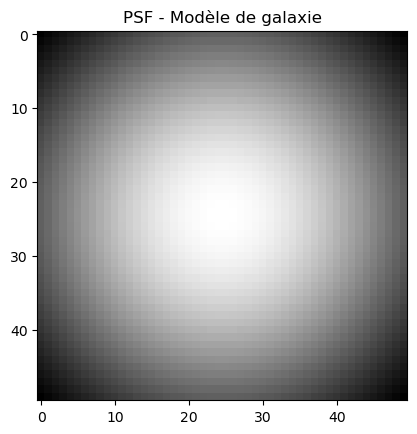

In [3]:
#PSF - galaxie circulaire

x, y = np.meshgrid(np.linspace(-1, 1, 50), np.linspace(-1, 1, 50))
d = np.sqrt(x*x + y*y)
sigma, mu = 1.0, 0.0
psf = np.exp(-( (d-mu)**2 / ( 2.0 * sigma**2 ) ) )

#PSF
plt.imshow(psf, cmap='gray')
plt.title("PSF - Modèle de galaxie")

plt.show()

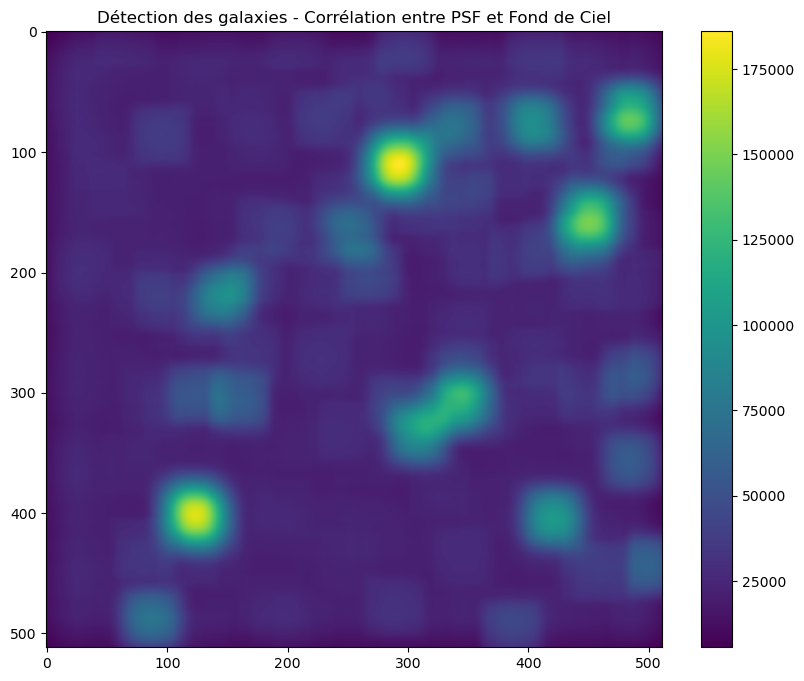

In [4]:
#corrélation
correlation_result = signal.convolve2d(fond_de_ciel_rouge, psf, mode='same')

#galaxies
plt.figure(figsize=(10, 8))
plt.imshow(correlation_result, cmap='viridis')
plt.title("Détection des galaxies - Corrélation entre PSF et Fond de Ciel")
plt.colorbar()

plt.show()

L'opération de corrélation cherche les zones qui ressemblent le plus à la PSF (le modèle de galaxie). Les galaxies détectées apparaissent comme des points brillants et localisés sur la carte de résultat, car ce sont les pics d'intensité qui montrent où la correspondance est la plus forte.

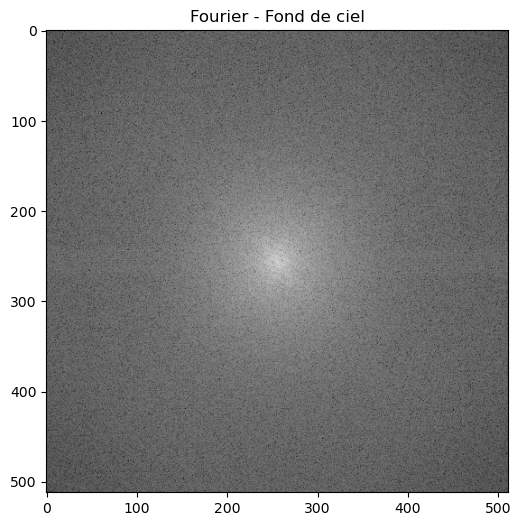

In [5]:
#1. calcul de FFT

fft_c = fft.fft2(fond_de_ciel_rouge)
fft_c_shift = fft.fftshift(fft_c)


magnitude_c = np.log(np.abs(fft_c_shift) + 1)

plt.figure(figsize=(6, 6))
plt.imshow(magnitude_c, cmap='gray')
plt.title("Fourier - Fond de ciel")

plt.show()

# Commentaire dans le markdown

L'information principale se trouve au centre (basses fréquences), ce qui représente le fond uniforme de l'image. La lumière diffuse s'étend vers les bords (hautes fréquences) et correspond aux petits détails et au bruit.

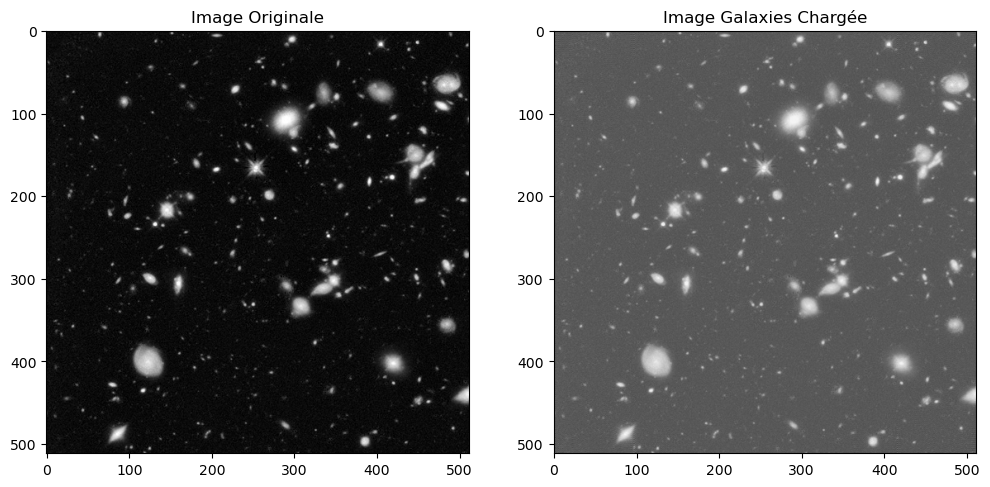

In [6]:
#2. l'image galaxies.npy

image_galaxies = np.load('image_galaxies.npy')

#comparaison

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(fond_de_ciel_rouge, cmap='gray')
ax[0].set_title('Image Originale')
ax[1].imshow(image_galaxies, cmap='gray')
ax[1].set_title('Image Galaxies Chargée')

plt.show()


L'Image Galaxies est plus lisse et moins détaillée que l'originale. Le bruit de fond a été réduit, ce qui suggère qu'elle a subi un filtrage

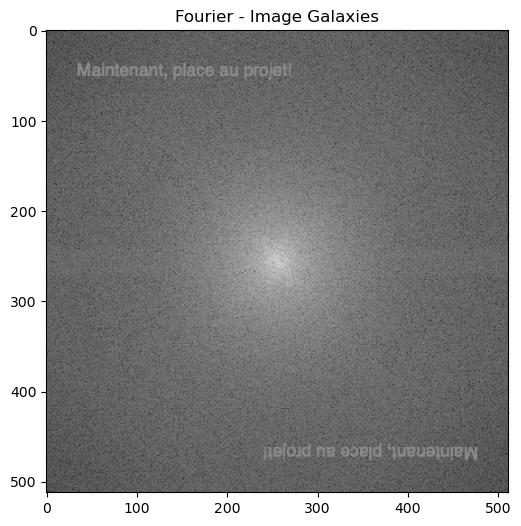

In [7]:
#3

#FFT de l'image utilisant scipy

fft_galaxies = fft.fft2(image_galaxies)
fft_galaxies_shft = fft.fftshift(fft_galaxies)
magnitude_galaxies = np.log(np.abs(fft_galaxies_shft) + 1)

plt.figure(figsize=(6, 6))
plt.imshow(magnitude_galaxies, cmap='gray')
plt.title("Fourier - Image Galaxies")

plt.show()


Spectre concentré au centre (basses fréquences), indiquant une absence de hautes fréquences due à un filtrage comme passe-bas.

Je m'intéresse au domaine du traitement des signaux, où nous utilisons beaucoup Fourier, car j'étudie l'ingénierie de contrôle.

Après le traitement de l'image, il a été possible d'observer un message également.

L'heure est venue de travailler sur le projet :)